# Kikuchi asymmetry — short-range figure

Short-range sweeps only (41 tilts, ±0.6°). Rebuilt on the corrected metric.

**What changed from the previous version of this figure**

- Uses `masked_com` from `kikuchi_com.py` — the centroid of the *union* of the two boxes.
  The old `calculate_box_asymmetry_score` took the midpoint of the two boxes' separate
  centroids, which algebraically cancels the intensity imbalance that is the signal.
- The mirrored box is `(N+1-hi, N+1-lo)`, not `(N-hi, N-lo)`. The old convention put a
  constant −0.511 px bias into every point.
- **Datasets swapped.** The PTO file previously used here
  (`1_slice_thickness/PTO_kikuchi_1_clice_...`) was run down zone axis **[010]**, which puts
  the polar *c*-axis on array axis 1 while the boxes and the tilt act on axis 0. Replaced with
  the 21 September re-run. Also note the `15_slice` / `1_slice_thickness` folders are *not* a
  thickness series — they are repeat runs of one setup (BTO's two files are byte-identical;
  boracite's differ by 1.3%, i.e. phonon seed only).
- Top-third box dropped. It reproduces to only 3.4 px between repeat runs (full box: 0.013 px),
  and it inflated the apparent significance of the off-by-one artefact.
- Axes in **mrad**, calibrated per material from the supercell extent.

In [1]:
import os
import itertools
import zipfile, io

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import LogNorm

plt.style.use("paper")   # ~/.config/matplotlib/stylelib

import sys
sys.path.insert(0, "..")
from polarisation_direction import P_REVERSED
from kikuchi_com import FULL_BOX, BORACITE_EXTENT, angular_box, mirror_box, masked_com, stream_patterns

# ── Electron wavelength and per-material reciprocal calibration ──────────────
# mrad per detector pixel = lambda / (in-plane supercell extent).
# Cross-check: PTO Bragg spacing is 30 px = 4.994 mrad = lambda/c. Correct.
# The two axes differ by c/a (~1.4%), so they are calibrated separately and the
# images are displayed on a mrad extent, which makes the angular scale isotropic.
_h, _m, _e, _c = 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19, 299792458.0
LAMBDA = _h / np.sqrt(2*_m*_e*300e3) / np.sqrt(1 + _e*300e3/(2*_m*_c**2)) * 1e10  # 0.019687 A

N = 4096
FOV_MRAD   = 215.0   # half-width shown; inside the antialias aperture, still contains the boxes
SCALEBAR   = 4.0     # inverse angstrom
TILT_SIGN  = -1      # x-axis convention carried over from the previous figure;
                     # applied to the tilt axis ONLY, identically for every row.

# The BaTiO3 CIF is polarised opposite to the PbTiO3 one (nominal moments
# -38.2 vs +17.9 uC/cm2 against the ideal cubic reference), so its curves are
# mirrored relative to the other two. Mirroring a structure through the plane
# perpendicular to P is exact -- no re-simulation needed -- but it reverses the
# tilt sense as well as the measured displacement:
#     M R_y(theta) M = R_y(-theta)   =>   y_aligned(t) = -y(-t)
# Negating the value alone would also invert the ODD (geometric) part of the
# curve, making BTO slope the wrong way for no physical reason.

MATERIALS = {
    "PTO": dict(
        formula=r"PbTiO$_3$", abbr="PTO",
        path="../data/short_range/PTO_short_range_21_sept_asymmetry_data.npz",
        cell=(3.9423, 3.8862), nrep=30),
    "BTO": dict(
        formula=r"BaTiO$_3$", abbr="BTO",
        path="../data/short_range/BTO_kikuchi_final_15_slice_asymmetry_data.npz",
        cell=(4.0230, 3.9905), nrep=30, flip_polar=True),
    "Boracite": dict(
        formula=r"Cu$_3$B$_7$ClO$_{13}$", abbr="boracite",
        path="../data/short_range/1_slice_thickness/boracite_kikuchi_1_slice_asymmetry_data.npz",
        cell=(17.1032, 17.1032), nrep=7,
        extent=(BORACITE_EXTENT, BORACITE_EXTENT))   # abTEM box, see kikuchi_com,
}
for cfg in MATERIALS.values():
    cfg.setdefault("flip_polar", False)
    a0, a1 = cfg["cell"]; n = cfg["nrep"]
    e0, e1 = cfg.get("extent", (n*a0, n*a1))                      # simulation box (A)
    cfg["mpp"] = (LAMBDA / e0 * 1e3, LAMBDA / e1 * 1e3)           # mrad per px
    cfg["kpp"] = (1.0 / e0,          1.0 / e1)                    # inverse angstrom per px
    cfg.setdefault("box", FULL_BOX)
# Boracite's antialias aperture is at 154 mrad (its larger box gives coarser angular
# pixels), so FULL_BOX's 108-208 mrad is out of reach, and 108-150 mrad sits in the faint
# edge of its pattern. Its box is placed on the bright Kikuchi bands instead, clear of the
# disks (< 35 mrad); same +-10 mrad width as FULL_BOX. The zero-tilt sign is the same for
# every window from 35 to 150 mrad and every width from 2 to 40 mrad, so this choice
# changes the magnitude, not the sign.
MATERIALS["Boracite"]["box"] = angular_box(*MATERIALS["Boracite"]["mpp"], r_mrad=(40.0, 100.0))
for k, cfg in MATERIALS.items():
    b, m = cfg["box"], cfg["mpp"]
    print(f"{k:9s} box {b}  = {(N//2 - b[1] + 1)*m[0]:.1f}-{(N//2 - b[0])*m[0]:.1f} mrad, "
          f"+-{(b[3] - b[2])/2*m[1]:.1f} mrad")

for k, cfg in MATERIALS.items():
    print(f"{k:9s} mrad/px = {cfg['mpp'][0]:.5f} / {cfg['mpp'][1]:.5f}   "
          f"A^-1/px = {cfg['kpp'][0]:.6f} / {cfg['kpp'][1]:.6f}   (axis0 polar / axis1)")


PTO       box (800, 1400, 1988, 2108)  = 108.0-207.7 mrad, +-10.1 mrad
BTO       box (800, 1400, 1988, 2108)  = 105.9-203.6 mrad, +-9.9 mrad
Boracite  box (1188, 1705, 1962, 2134)  = 40.0-100.0 mrad, +-10.0 mrad
PTO       mrad/px = 0.16646 / 0.16887   A^-1/px = 0.008455 / 0.008577   (axis0 polar / axis1)
BTO       mrad/px = 0.16312 / 0.16445   A^-1/px = 0.008286 / 0.008353   (axis0 polar / axis1)
Boracite  mrad/px = 0.11628 / 0.11628   A^-1/px = 0.005906 / 0.005906   (axis0 polar / axis1)


In [2]:
CACHE = "cache_shortrange"
os.makedirs(CACHE, exist_ok=True)


def tilts(path):
    zf = zipfile.ZipFile(path)
    with zf.open("tilt_y_values.npy") as h:
        return np.load(io.BytesIO(h.read()))


def frame(path, k):
    return next(itertools.islice(stream_patterns(path), k, k + 1))


# Row 3 is the NAIVE alternative the Kikuchi method is being compared against:
# a whole-pattern intensity mismatch about the centre. It is kept deliberately
# crude, because the point of the row is that it is NOT robust.
#
# Why it fails: the polar asymmetry reverses sign between the low-angle and the
# high-angle regime, and the inner disc carries 54-75% of the total intensity.
# The whole-pattern half-sum is therefore dominated by the direct beam and
# reports the OPPOSITE sign to the Kikuchi bands. The annular version over the
# same radii as the boxes is computed alongside it to make that explicit.
_yy, _xx = np.mgrid[0:N, 0:N]
_R = np.hypot(_yy - N//2, _xx - N//2)


def annulus_halves(box):
    """Annulus over the box's radii, split into the paired low/high halves."""
    r_in, r_out = N//2 - box[1] + 1, N//2 - box[0]          # FULL_BOX: 649, 1248 px
    a = (_R >= r_in) & (_R <= r_out)
    return a[1:N//2], a[N//2+1:]


def process(name, cfg):
    """Corrected COM on the polar axis, the axis-1 control, and the annular
    intensity mismatch. One streaming pass over the 5.5 GB file."""
    npy = os.path.join(CACHE, f"{name}.npz")
    box = tuple(int(v) for v in cfg["box"])
    if os.path.exists(npy):
        d = np.load(npy)
        # caches written before per-material boxes carry no "box"; those used FULL_BOX
        if (tuple(int(v) for v in d["box"]) if "box" in d.files else FULL_BOX) == box:
            return {k: d[k] for k in d.files}

    box1, box2 = box, mirror_box(box)
    A_LO, A_HI = annulus_halves(box)
    com, ctrl, mism, mism_ann = [], [], [], []
    zero = None
    t = tilts(cfg["path"])
    i0 = int(np.argmin(abs(t)))
    for i, p in enumerate(stream_patterns(cfg["path"])):
        com.append(masked_com(p, box1, box2, 0))
        ctrl.append(masked_com(p, box1, box2, 1))
        # Equal, properly paired halves: row 0 is the unpaired Nyquist row and
        # row N/2 is the centre, so both are excluded.
        # Computed (high index - low index); negated with the COM below.
        lo_w, hi_w = p[1:N//2].sum(), p[N//2+1:].sum()
        mism.append((hi_w - lo_w) / (hi_w + lo_w) * 100)
        lo_a = p[1:N//2][A_LO].sum()
        hi_a = p[N//2+1:][A_HI].sum()
        mism_ann.append((hi_a - lo_a) / (hi_a + lo_a) * 100)
        if i == i0:
            zero = p.copy()
    out = dict(tilt=t, com=np.array(com), ctrl=np.array(ctrl),
               mismatch=np.array(mism), mismatch_ann=np.array(mism_ann), zero=zero,
               box=np.array(box))
    np.savez_compressed(npy, **out)
    return out


results = {k: process(k, cfg) for k, cfg in MATERIALS.items()}

# Sign convention shared with the disk notebooks: POSITIVE = TOP (low row index) BRIGHTER.
# masked_com is + towards higher index and the mismatch was computed (high - low), so
# both are negated here; the cache keeps the raw values.
for r in results.values():
    for key in ("com", "mismatch", "mismatch_ann"):
        if key in r:
            r[key] = -r[key]
for k, r in results.items():
    print(f"{k:9s} n={len(r['tilt'])}  COM {r['com'].min():+8.1f}..{r['com'].max():+8.1f} px")


PTO       n=41  COM    -64.3..  +105.4 px
BTO       n=41  COM    -98.8..  +104.5 px
Boracite  n=41  COM    -93.6..  +109.3 px


### Polarisation signature

A polar offset is **even** in tilt; a purely geometric response is odd and cancels. Array
axis 1 is non-polar, so it acts as a control within the same dataset — it should show no even
component. Quoting an SEM across tilt points would be wrong here: repeat runs show the
tilt-to-tilt structure is deterministic (r = 1.000), not noise.

In [3]:
def even_part(t, y):
    i0 = int(np.argmin(abs(t))); n = min(i0, len(t) - 1 - i0)
    return t[i0+1:i0+1+n][::-1], (y[i0-n:i0] + y[i0+1:i0+1+n][::-1]) / 2


print(f"{'material':9s} {'e_rms polar':>12s} {'e_rms control':>14s} {'ratio':>7s}   (px)")
for k, r in results.items():
    _, ep = even_part(r["tilt"], r["com"])
    _, ec = even_part(r["tilt"], r["ctrl"])
    print(f"{k:9s} {ep.std(ddof=1):12.2f} {ec.std(ddof=1):14.2f} {ep.std(ddof=1)/ec.std(ddof=1):7.1f}")

print(f"\n{'material':9s} {'D0 as simulated':>18s} {'D0 aligned to PTO':>20s}")
for k, r in results.items():
    kpp0 = MATERIALS[k]["kpp"][0]
    i0 = int(np.argmin(abs(r["tilt"])))
    raw = r["com"][i0] * kpp0
    print(f"{k:9s} {raw:>+13.4f} A^-1 {(-raw if MATERIALS[k]['flip_polar'] else raw):>+15.4f} A^-1"
          f"   {'(flipped)' if MATERIALS[k]['flip_polar'] else ''}")


material   e_rms polar  e_rms control   ratio   (px)
PTO              22.21           0.21   107.9
BTO              10.48           0.29    36.6
Boracite          7.44           0.38    19.6

material     D0 as simulated    D0 aligned to PTO
PTO             -0.2051 A^-1         -0.2051 A^-1   
BTO             +0.0677 A^-1         -0.0677 A^-1   (flipped)
Boracite        -0.0737 A^-1         -0.0737 A^-1   


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


saved figures/kikuchi_short_range.{pdf,png}


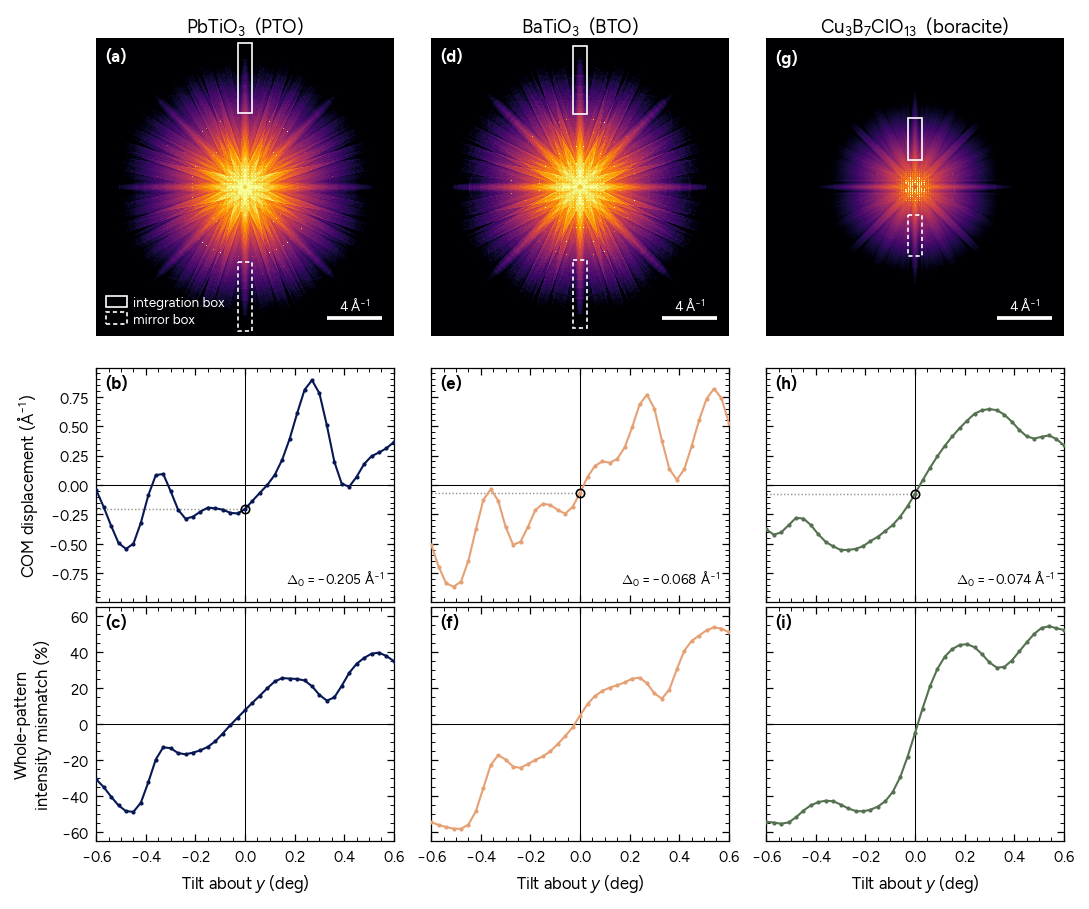

In [4]:
def short_range_figure(raw=False, aligned=False, final=False):
    """raw=True: no polar alignment, tilt as simulated, 'unflipped_' prefix.
    aligned=True: every material mirrored to PTO's polarisation (P_REVERSED), 'aligned_' prefix.
    final=True: common polarisation frame with P towards the TOP box, i.e. PTO mirrored and
    BTO/boracite as simulated (both are built reversed relative to PTO); 'corrected_final/' prefix."""
    pre = "unflipped_" if raw else "aligned_" if aligned else "corrected_final/corrected_final_" if final else ""
    # ── Figure: 180 mm double column, styled by the paper stylesheet (set in cell 1) ───
    MM = 1 / 25.4
    FG, ZERO, GUIDE = "black", "black", "#9a9a96"   # text, zero lines, guide line
    COLOURS = dict(zip(MATERIALS, plt.rcParams["axes.prop_cycle"].by_key()["color"]))

    fig, axes = plt.subplots(
        3, 3, figsize=(180*MM, 150*MM),
        gridspec_kw={"height_ratios": [1.5, 1.0, 1.0]},
        layout="constrained",
    )
    fig.get_layout_engine().set(h_pad=0.01, w_pad=0.01, hspace=0.015, wspace=0.03)

    letters = iter("abcdefghi")

    com_all  = np.concatenate([results[k]["com"] * MATERIALS[k]["kpp"][0] for k in MATERIALS])
    mism_all = np.concatenate([results[k]["mismatch"] for k in MATERIALS])
    com_lim  = np.abs(com_all).max()  * 1.12
    mism_lim = np.abs(mism_all).max() * 1.12


    def panel_label(ax, txt, colour=FG):
        ax.text(0.03, 0.965, f"({txt})", transform=ax.transAxes, va="top", ha="left",
                fontsize=8, fontweight="bold", color=colour)


    for col, (name, cfg) in enumerate(MATERIALS.items()):
        res = results[name]
        mpp0, mpp1 = cfg["mpp"]
        kpp0, kpp1 = cfg["kpp"]
        t_plot = (1 if raw else TILT_SIGN) * res["tilt"]

        # ══ Row 0: zero-tilt pattern, shown on a mrad extent so the angular ══════
        #           scale is isotropic despite the 1.4% c/a pixel anisotropy
        ax = axes[0, col]
        h0, h1 = int(FOV_MRAD / mpp0), int(FOV_MRAD / mpp1)
        img = res["zero"][N//2-h0:N//2+h0, N//2-h1:N//2+h1]
        # colour limits from inside the antialias aperture (N/3 px radius) only; boracite's
        # 154 mrad aperture sits inside the 215 mrad field of view
        yy, xx = np.ogrid[-h0:h0, -h1:h1]
        inside = np.hypot(yy*mpp0, xx*mpp1) < 0.97 * N * min(mpp0, mpp1) / 3
        vmin, vmax = np.percentile(img[inside & (img > 0)], [35, 99.8])
        kx, ky = h1*kpp1, h0*kpp0          # half-widths in inverse angstrom
        ax.imshow(np.clip(img, vmin, vmax), cmap="inferno", origin="upper",
                  extent=[-kx, kx, ky, -ky],
                  aspect="equal", norm=LogNorm(vmin=vmin, vmax=vmax), rasterized=True)

        for b, ls in ((cfg["box"], "-"), (mirror_box(cfg["box"]), (0, (2.5, 1.8)))):
            lo, hi, x0, x1 = b
            ax.add_patch(Rectangle(((x0-N//2)*kpp1, (lo-N//2)*kpp0),
                                   (x1-x0)*kpp1, (hi-lo)*kpp0,
                                   lw=0.8, edgecolor="white", facecolor="none", linestyle=ls))

        # scale bar, bottom right (legend lives bottom left on the first panel)
        x_hi, y_lo = kx*0.92, ky*0.88
        ax.plot([x_hi - SCALEBAR, x_hi], [y_lo, y_lo], color="white", lw=1.8,
                solid_capstyle="butt", zorder=5)
        ax.text(x_hi - SCALEBAR/2, y_lo - ky*0.035, rf"{SCALEBAR:.0f} $\mathrm{{\AA}}^{{-1}}$",
                color="white", ha="center", va="bottom", fontsize=6.5, zorder=5)

        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        panel_label(ax, next(letters), colour="white")
        if final:                                   # P points to the top (solid) box
            ax.annotate("", xy=(-kx*0.80, -ky*0.72), xytext=(-kx*0.80, -ky*0.44),
                        arrowprops=dict(arrowstyle="-|>", color="white", lw=1.0))
            ax.text(-kx*0.74, -ky*0.58, "P", color="white", va="center", fontsize=7, fontweight="bold")
        ttl = rf"{cfg['formula']}  ({cfg['abbr']})"
        ax.set_title(ttl, pad=3, fontsize=9)

        # ══ Row 1: corrected COM along the polar axis ════════════════════════════
        ax = axes[1, col]
        ax.axhline(0, color=ZERO, lw=0.5, zorder=0)
        ax.axvline(0, color=ZERO, lw=0.5, zorder=0)
        # y_aligned(t) = -y(-t); the tilt grid is symmetric and ascending, so this
        # is a reversal plus a negation. Applied to both rows so they stay consistent.
        flip = (lambda v: -v[::-1]) if (P_REVERSED[name] if aligned else (not P_REVERSED[name]) if final else cfg["flip_polar"]) and not raw else (lambda v: v)
        y_invA = flip(res["com"]) * kpp0
        ax.plot(t_plot, y_invA, "-o", ms=2.0, color=COLOURS[name],
                markeredgewidth=0, zorder=3)

        # y(0) is exactly the even part at zero tilt, so it IS the polarisation
        # offset. The zero CROSSING is a poor observable: it sits at -y(0)/slope,
        # and the slope varies 4.6x between these materials.
        i0 = int(np.argmin(abs(res["tilt"])))
        y0 = y_invA[i0]
        ax.plot([t_plot.min(), 0], [y0, y0], color=GUIDE, lw=0.7, ls=(0, (1, 1.4)), zorder=2)
        ax.plot([0], [y0], "o", ms=4.0, mfc="none", mec=FG, mew=0.8, zorder=4)
        ax.text(0.97, 0.06, rf"$\Delta_0={y0:+.3f}\ \mathrm{{\AA}}^{{-1}}$", transform=ax.transAxes,
                ha="right", va="bottom", fontsize=6.5, color=FG)
        ax.set_ylim(-com_lim, com_lim)
        ax.set_xlim(t_plot.min(), t_plot.max())
        if col == 0:
            ax.set_ylabel(r"COM displacement ($\mathrm{\AA}^{-1}$)")
        else:
            ax.set_yticklabels([])
        ax.set_xticklabels([])
        panel_label(ax, next(letters))

        # ══ Row 2: whole-pattern intensity mismatch ══════════════════════════════
        ax = axes[2, col]
        ax.axhline(0, color=ZERO, lw=0.5, zorder=0)
        ax.axvline(0, color=ZERO, lw=0.5, zorder=0)
        ax.plot(t_plot, flip(res["mismatch"]), "-o", ms=2.0, color=COLOURS[name],
                markeredgewidth=0, zorder=3)
        ax.set_ylim(-mism_lim, mism_lim)
        ax.set_xlim(t_plot.min(), t_plot.max())
        ax.set_xlabel(r"Tilt about $y$ (deg)")
        if col == 0:
            ax.set_ylabel("Whole-pattern\nintensity mismatch (%)")
        else:
            ax.set_yticklabels([])
        panel_label(ax, next(letters))

    # one legend for the box overlays, bottom-left of the first pattern
    leg = axes[0, 0].legend(
        [Rectangle((0, 0), 1, 1, ec="white", fc="none", lw=0.8),
         Rectangle((0, 0), 1, 1, ec="white", fc="none", lw=0.8, ls=(0, (2.5, 1.8)))],
        ["integration box", "mirror box"],
        loc="lower left", handleheight=0.9,
    )
    for txt in leg.get_texts():
        txt.set_color("white")

    fig.savefig(f"figures/{pre}kikuchi_short_range.pdf")
    fig.savefig(f"figures/{pre}kikuchi_short_range.png")
    print(f"saved figures/{pre}kikuchi_short_range.{{pdf,png}}")
    plt.show()


short_range_figure()

### Unflipped version
Raw values as simulated: no `flip_polar` alignment, and `TILT_SIGN` = +1 (tilt axis not mirrored). Saved with the `unflipped_` prefix.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


saved figures/unflipped_kikuchi_short_range.{pdf,png}


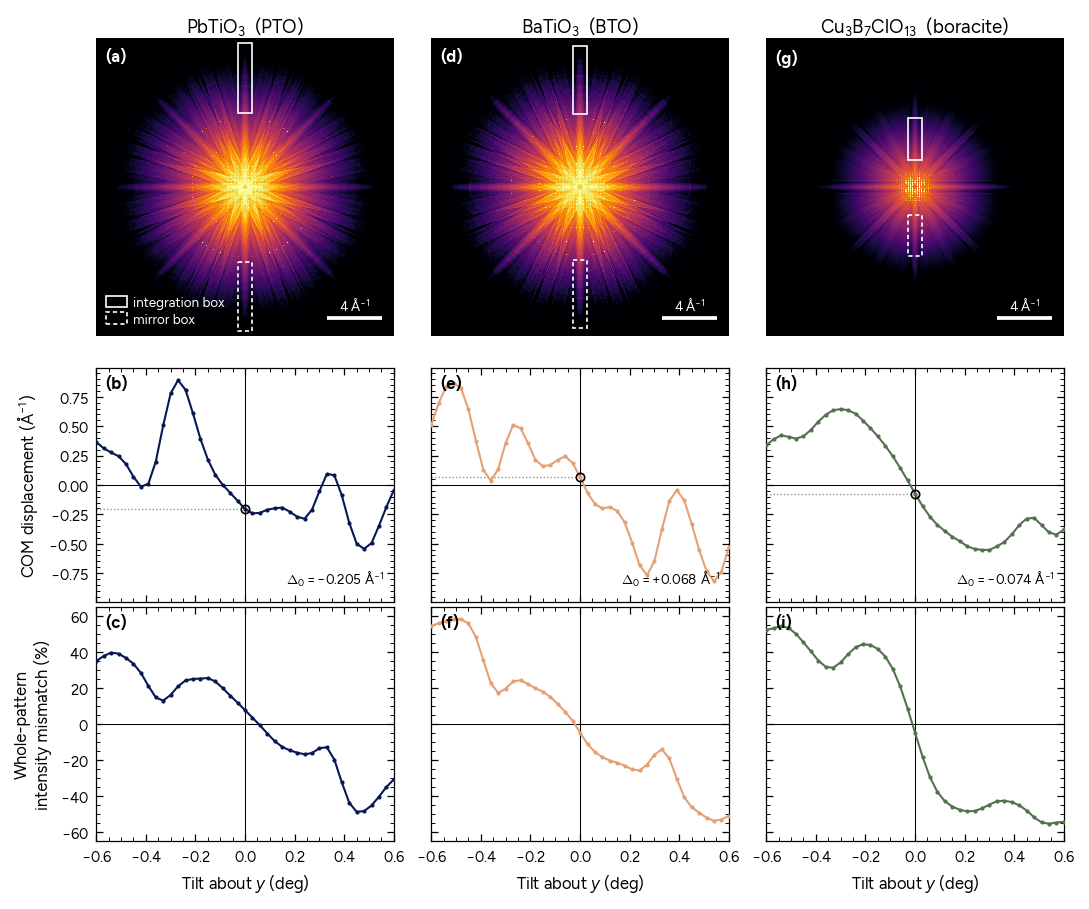

In [5]:
short_range_figure(raw=True)

### Correctly oriented version
What the sims would give had every structure been polarised the same way along the measured
axis (as PTO, +x). From `polarisation_direction.py`: BTO and boracite were simulated with P
reversed relative to PTO (lab P_x = +38.2, -17.9, -0.71 uC/cm2), so both are mirrored,
y(t) -> -y(-t); PTO is unchanged. Tilt axis uses the same `TILT_SIGN` convention as the main
figure. Differs from the main figure only in boracite. Saved with the `aligned_` prefix.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


saved figures/aligned_kikuchi_short_range.{pdf,png}


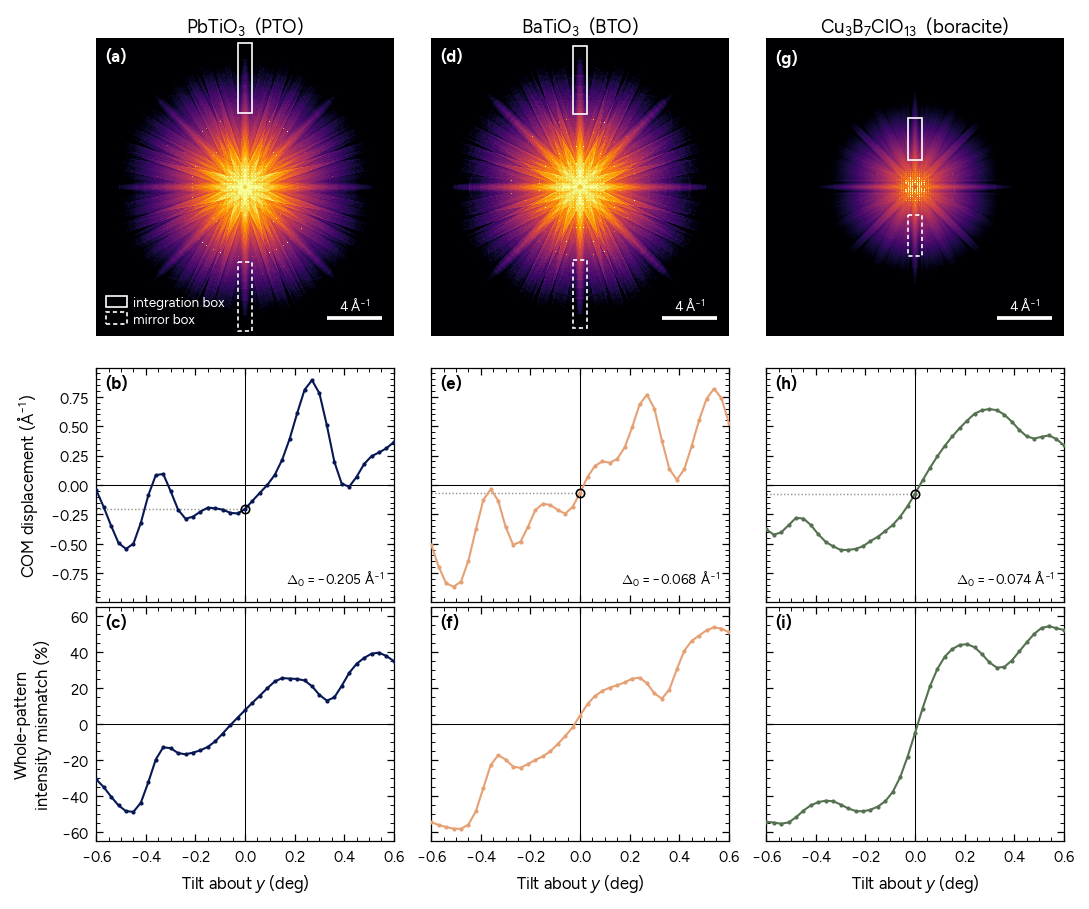

In [6]:
short_range_figure(aligned=True)

**Reading the figure.** Row (a)–(c): simulated CBED pattern at zero tilt, log intensity,
with the integration box and its mirror. Row (d)–(f): corrected centre-of-mass displacement
along the polar axis. Row (g)–(i): whole-pattern intensity mismatch between the two halves.

The polarisation signature is the part of the curve that does **not** invert when the tilt is
reversed. Columns share y-limits, so the three materials are directly comparable.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


saved figures/corrected_final/corrected_final_kikuchi_short_range.{pdf,png}


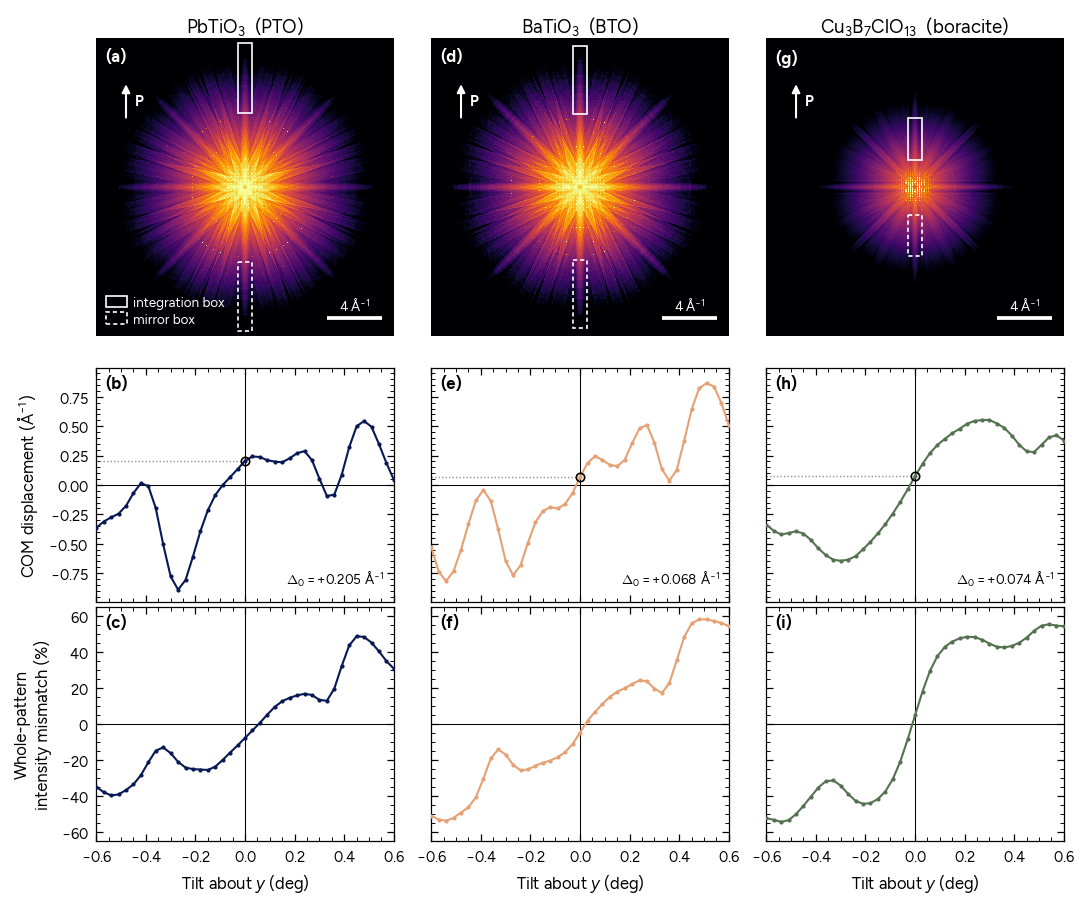

In [7]:
short_range_figure(final=True)